# Gradient Ascent Pulse Engineering

The goal is to find control waveforms that make a transmon implement a desired quantum gate with high fidelity.

We start with the controlled Schrödinger equation,
$$
i\frac{d}{dt}|\psi(t)\rangle
=H(t)|\psi(t)\rangle,
$$

and split the Hamiltonian into drift and control:
$$
H(t)=H_d+\sum_{j}u_j(t)H_j.
$$

GRAPE optimizes the control amplitudes to maximize the fidelity with a target gate. The output is a different optimized pulse for each target gate ($X$, $Y$, $H$, $T$, ...).

We use JAX for the automatic differentiation, to calculate the gradient. When you create an array with jnp.array(...) or run a JAX function, JAX does not store it in regular CPU RAM. It allocates it directly in the GPU’s VRAM as a jax.Array. JAX uses accelerated linear algebra, using internal computation graphs, fuses multiple operations into a single GPU machine-code kernel and parallel tree reductions like ```jax.lax.associative_scan```. Finally, Asynchronous dispatch, Python doesn't wait for the GPU to finish the math it immediately returns a "future" (a reference to the result being computed) and continues executing the next line of Python code.

In [4]:
import sys
!{sys.executable} -m pip install plotly ipywidgets

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 14.6 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 490.6/490.6 KB 12.5 MB/s eta 0:00:0000:01


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import plotly.graph_objects as go
import ipywidgets as widgets
from scipy.linalg import expm
from IPython.display import display, clear_output
import jax
import jax.numpy as jnp
jax.config.update("jax_enable_x64", True)

import sys
from pathlib import Path
root_path = Path.cwd().parent
sys.path.append(str(root_path / "src"))
from gates import *
from evolution import propagator_jax
from optimization import grape_optimization, constraints, scipy_objective, finite_difference_gradient, gate_infidelity

### 1. The Model

We pick a two-level transmon model in a frame rotating at the drive frequency, with a fixed detuning and two microwave control quadratures.
$$
H(t)=
\frac{\Delta}{2}\sigma_z+
\frac{u_x(t)}{2}\sigma_x+
\frac{u_y(t)}{2}\sigma_y
$$
where $\Delta = 0.2\Omega_{max}$ is our detunning frequency, $\Omega_{max} = 1.0$.

Our controls can be rewritten in polar form:
$$
u_x(t)=\Omega(t)\cos\phi(t), \qquad
u_y(t)=\Omega(t)\sin\phi(t)
$$
The total drive amplitude is therefore:
$$
\Omega(t)=\sqrt{u_x(t)^2+u_y(t)^2}
$$
Since the physical drive cannot exceed its maximum allowed amplitude, we impose:
$$
\boxed{u_x(t)^2+u_y(t)^2\leq\Omega_{\max}^2}
$$

We will chose our parametrization to be the following: 

| Parameter                  | Value                               |
| -------------------------- | ----------------------------------- |
| Gate duration $T$          | $5/\Omega_{max}$                    |
| Segments $N$               | 50                                  |
| Segment duration $\Delta t$| $T/N$                               |
| Control bounds             | $u_x(t)^2+u_y(t)^2\le\Omega_{max}^2$|
| Initial pulse              | random                              |

In [6]:
OMEGA_MAX = 1.0
DELTA = 0.2 * OMEGA_MAX

T = 5.0 / OMEGA_MAX
N = 50
DT = T / N

U_MIN = -OMEGA_MAX
U_MAX = OMEGA_MAX
GATE = "H"

TARGET_GATES = {
    "X": jnp.asarray(X, dtype=jnp.complex128),
    "Y": jnp.asarray(Y, dtype=jnp.complex128),
    "Z": jnp.asarray(Z, dtype=jnp.complex128),
    "H": jnp.asarray(H, dtype=jnp.complex128),
    "S": jnp.asarray(S, dtype=jnp.complex128),
    "T": jnp.asarray(T, dtype=jnp.complex128),
    "SX": jnp.asarray(SX, dtype=jnp.complex128),
    "SY": jnp.asarray(SY, dtype=jnp.complex128),
}

print(f"Maximum control amplitude: {OMEGA_MAX}")
print(f"Detuning:                  {DELTA}")
print(f"Total duration:            {T}")
print(f"Number of segments:        {N}")
print(f"Segment duration:          {DT}")
print(f"Optimization variables:    {2 * N}")

Maximum control amplitude: 1.0
Detuning:                  0.2
Total duration:            5.0
Number of segments:        50
Segment duration:          0.1
Optimization variables:    100


The key operation is computing the propagator for each segment. Since our Hamiltonian is a linear combination of Pauli matrices, we can use an analytic matrix exponential instead of repeatedly calling a general-purpose matrix-exponential routine.

To compute the exponential, recall that a $2×2$ matrix satisfies its own characteristic polynomial as a
stated in the Cayley-Hamilton theorem. This means that $A$ is a solution of the matrix equation
$$
A^2 - tr(A)A + (\det{A})id = 0
$$
Assume that $tr(A)=0$. Then we get
$$
A^2 = - (\det{A})id
$$
Hence by absolute convergence, if $\det{A} \ne 0$, we have
$$
\begin{align*}
e^{A} &= \sum_{i=0}^{\infty}\frac{A^i}{i!}\\ 
      &= id \sum_{i=0}^{\infty}\frac{(\sqrt{\det{A}})^{2i}}{2i!} + \frac{A}{\sqrt{\det{A}}}\sum_{i=0}^{\infty}\frac{(\sqrt{\det{A}})^{2i+1}}{(2i+1)!}\\ 
      &= \cos(\sqrt{\det{A}})id + \sin(\sqrt{\det{A}})\frac{A}{\det{A}}
\end{align*}
$$
Now its enough to take $A = -i\delta tH_k$, where we have
$$
\begin{align*}
H_k &= \frac12(\Delta Z + u_{x,k}X+u_{y,k}Y) \\
\det{(-i\delta tH_k)} &= \left(\frac{\delta t}{2}\right)^2+ \underbrace{[\Delta^2 + u_{x,k}^2+u_{y,k}^2]}_{r_k^2} \\
U_k &= \cos\left(\frac{r_k \delta t}{2}\right)I - \left(\frac{2i}{r_k}\right)\sin\left(\frac{r_k \delta t}{2}\right)H_k
\end{align*}
$$
And thus the total propagator
$$
U(T) = \prod_{k=0}^{N-1} U_{N-1-k} = U_{N-1}...U_1U_0
$$

In [7]:
rng = np.random.default_rng()

def random_pulse():
    """Generate random initial controls with amplitude constraint."""
    phi = rng.uniform(0.0, 2.0 * np.pi, N)
    amplitude = OMEGA_MAX * np.sqrt(rng.uniform(0.0, 1.0, N))

    return jnp.asarray(np.concatenate((amplitude * np.cos(phi), amplitude * np.sin(phi))))

cons = constraints(N, OMEGA_MAX)

U_target = TARGET_GATES[GATE]

### 2. GRAPE optimization
We parameterize the pulse by its $2N=100$ control amplitudes:
$$
\mathbf{u}=
(u_{x,0},\ldots,u_{x,49},
u_{y,0},\ldots,u_{y,49}).
$$

For a target gate $U_{\mathrm{target}}$, we want to find the controls that maximize the average gate fidelity:
$$
\max_{\mathbf{u}} F_{\mathrm{avg}}
\quad\text{subject to}\quad
1 - \frac{u_{x,k}^2+u_{y,k}^2}{\Omega_{max}^2}\geq 0
$$

Equivalently, we minimize the infidelity:
$$
J(\mathbf{u})=1-F_{\mathrm{avg}}.
$$

The parameters of $\mathbf u$ determine the Hamiltonians, which determine the propagator $U(T;\mathbf u)$, which determines the fidelity with our target gate $U_{\mathrm{target}}$.

So we define the objective function
$$
J(\mathbf u)=1-F_{\mathrm{avg}}
\left(U_{\mathrm{target}},U(T;\mathbf u)\right).
$$

Our goal is to solve
$$
\boxed{
\min_{\mathbf u}J(\mathbf u)
\quad\text{subject to}\quad
1 - \frac{u_{x,k}^2+u_{y,k}^2}{\Omega_{max}^2}\geq 0 \quad k=0,\ldots,N-1
}
$$

This is a constrained, nonlinear and non-convex optimization problem with 100 decision variables.

To solve this, we define the Lagrangian:
$$
\mathcal{L}(\mathbf{u}, \boldsymbol{\lambda}) = J(\mathbf{u}) - \sum_{k=0}^{N-1} \lambda_k \left( 1 - \frac{u_{x,k}^2 + u_{y,k}^2}{\Omega_{\max}^2} \right)
$$
where $\lambda_k \ge 0$ are the Lagrange multipliers and the $k$-th constraint is:
$$
g_k(u_{x,k}, u_{y,k}) = 1 - \frac{u_{x,k}^2 + u_{y,k}^2}{\Omega_{\max}^2} \ge 0
$$

At an optimal solution $\mathbf{u}^*$, the KKT conditions must hold:
1. Stationarity:
$$
\nabla_{\mathbf{u}} \mathcal{L}(\mathbf{u}^*, \boldsymbol{\lambda}^*) = \nabla_{\mathbf{u}} J(\mathbf{u}^*) + \sum_{k=0}^{N-1} \lambda_k^* \frac{2}{\Omega_{\max}^2} \begin{pmatrix} u_{x,k}^* \\ u_{y,k}^* \end{pmatrix} = \mathbf{0}
$$
2. Primal Feasibility
$$
u_{x,k}^{*2} + u_{y,k}^{*2} \le \Omega_{\max}^2 \quad \forall k
$$
3. Dual Feasibility
$$
\lambda_k^* \ge 0 \quad \forall k
$$
4. Complementary Slackness:
$$
\lambda_k^* \left( 1 - \frac{u_{x,k}^{*2} + u_{y,k}^{*2}}{\Omega_{\max}^2} \right) = 0 \quad \forall k
$$

In [8]:
N_RESTARTS = 5
MAX_ITER = 500

optimization_results = []

for restart in range(N_RESTARTS):

    initial_controls = random_pulse()

    optimization = grape_optimization(DELTA, initial_controls, DT, U_target, cons, maxiter=MAX_ITER)

    results = optimization["result"]

    initial_fidelity = 1.0 - float(gate_infidelity(DELTA, initial_controls, DT, U_target))

    fidelities = [initial_fidelity] + optimization["iteration_fidelities"]

    pulses = [np.asarray(initial_controls).copy()] + optimization["pulse_history"]

    final_fidelity = np.clip(fidelities[-1], 0.0, 1.0)

    optimization_results.append({
        "restart": restart,
        "fidelities": fidelities,
        "pulses": pulses,
        "final_fidelity": final_fidelity,
        "result": results
    })

    print(
        f"Restart {restart + 1}/{N_RESTARTS} | "
        f"Initial F = {initial_fidelity*100:.2f}% | "
        f"Final F = {final_fidelity*100:.2f}% | "
        f"Iterations = {results.nit} | "
        f"Success = {results.success}"
    )

best_run = max(
    optimization_results,
    key=lambda item: item["final_fidelity"]
)

best_result = best_run["result"]
best_controls = np.asarray(best_run["pulses"][-1]).reshape(2, N) 
best_ux = best_controls[0]
best_uy = best_controls[1]
best_fidelity = best_run["final_fidelity"]
U_best = np.asarray(propagator_jax(DELTA, best_controls, DT))
unitarity_error = np.linalg.norm(U_best.conj().T @ U_best - np.eye(2))
_, gradient = scipy_objective(best_run["pulses"][-1], DELTA, DT, U_target)

print("\nBest optimization result")
print("------------------------")
print(f"Best fidelity: {best_fidelity*100}%")
print(f"Fidelity improvement: {(best_fidelity - best_run['fidelities'][0]) * 100:.2f}%")
print("Iterations:", best_result.nit)
print(f"Unitarity error: {unitarity_error:.3e}")
print(f"Gradient norm: {np.linalg.norm(gradient):.3e}")
print("Final propagator:")
print(U_best)

Restart 1/5 | Initial F = 39.07% | Final F = 100.00% | Iterations = 19 | Success = True
Restart 2/5 | Initial F = 34.29% | Final F = 100.00% | Iterations = 22 | Success = True
Restart 3/5 | Initial F = 38.08% | Final F = 100.00% | Iterations = 24 | Success = True
Restart 4/5 | Initial F = 40.81% | Final F = 100.00% | Iterations = 18 | Success = True
Restart 5/5 | Initial F = 35.22% | Final F = 100.00% | Iterations = 20 | Success = True

Best optimization result
------------------------
Best fidelity: 99.99999999999665%
Fidelity improvement: 60.93%
Iterations: 19
Unitarity error: 5.552e-16
Gradient norm: 8.549e-08
Final propagator:
[[ 1.50541669e-07-0.70710671j  1.27856312e-07-0.70710685j]
 [-1.27856312e-07-0.70710685j  1.50541669e-07+0.70710671j]]


At iteration $m$, SLSQP solves an active-set Quadratic Program (QP) for the step $\mathbf{p}$ and multipliers $\lambda_k$ simultaneously using the linear system:
$$
\begin{bmatrix} B & \nabla g_{k_1} & \nabla g_{k_2} & \cdots & \nabla g_{k_M} \\ \nabla g_{k_1}^T & 0 & 0 & \cdots & 0 \\ \nabla g_{k_2}^T & 0 & 0 & \cdots & 0 \\ \vdots & \vdots & \vdots & \ddots & \vdots \\ \nabla g_{k_M}^T & 0 & 0 & \cdots & 0 \end{bmatrix} \begin{bmatrix} \mathbf{p} \\ \lambda_{k_1} \\ \lambda_{k_2} \\ \vdots \\ \lambda_{k_M} \end{bmatrix} = \begin{bmatrix} -\nabla J \\ -g_{k_1} \\ -g_{k_2} \\ \vdots \\ -g_{k_M} \end{bmatrix}
$$
Compactly written as:
$$
\begin{align*}
&\begin{bmatrix} B & {\nabla \mathbf{g}}^T \\ \nabla \mathbf{g} & 0 \end{bmatrix} \begin{bmatrix} \mathbf{p} \\ \boldsymbol{\lambda} \end{bmatrix} = \begin{bmatrix} -\nabla J(\mathbf{u}^{(m)}) \\ -\mathbf{g} \end{bmatrix}\\
&\Leftrightarrow \begin{cases}
  B \mathbf{p} + {\nabla \mathbf{g}}^T \boldsymbol{\lambda} = -\nabla J \quad (\text{Stationarity})\\
  \nabla \mathbf{g} \cdot \mathbf{p} = -\mathbf{g} \quad(\text{Feasibility})\\
\end{cases}
\end{align*}
$$
where:
- $\nabla \mathbf{g} \in \mathbb{R}^{M \times 2N}$ is the matrix whose rows are the active constraint gradients $\nabla g_k^T$.
- $\mathbf{g} \in \mathbb{R}^M$ is the vector of constraint values $g_k$.
- $B \in \mathbb{R}^{2N \times 2N}$ is the curvature matrix (approximation of the Lagrangian Hessian $\nabla_{\mathbf{u}\mathbf{u}}^2 \mathcal{L}$). Initialized as $\mathbb{I}_{2N \times 2N}$ and updated each turn via BFGS.

Instead of inverting the full matrix, SLSQP solves it stably using Null-Space Projection via QR decomposition of ${\nabla \mathbf{g}}^T$: 
$$
{\nabla \mathbf{g}}^T = \begin{bmatrix} Q_1 & Q_2 \end{bmatrix} \begin{bmatrix} R \\ 0 \end{bmatrix}
$$
The step $\mathbf{p}$ decomposes into two orthogonal components:
$$
\mathbf{p} = \mathbf{p}_Y + \mathbf{p}_Z
$$
Feasibility step ($\mathbf{p}_Y$): Corrects any constraint violation:
$$
\nabla \mathbf{g} \cdot \mathbf{p}_Y = -\mathbf{g} \implies \mathbf{p}_Y = -Q_1 R^{-T} \mathbf{g}
$$
Descent step ($\mathbf{p}_Z$): Minimizes infidelity along the allowed boundary directions:
$$
\mathbf{p}_Z = -Q_2 \big(Q_2^T B Q_2\big)^{-1} Q_2^T \big(\nabla J + B \mathbf{p}_Y\big)
$$
Active-Set Check: SLSQP calculates the multipliers
$$
\boldsymbol{\lambda} = R^{-1} Q_1^T (-\nabla J - B\mathbf{p})
$$
Thus $\mathbf{u}$ is updated via 
$$
\mathbf{u}^{(m+1)} = \mathbf{u}^{(m)} + \alpha \mathbf{p}
$$
where $\alpha \in (0, 1]$ chosen via the Merit Function Line Search.

Since our probelm is non-convex our objective function can contain multiple local minima and stationary points. SLSQP generally converges towards a local solution near its initial point, rather than exploring the entire parameter space.

This is why we use multiple random initializations. They allow us to explore different regions of the parameter space and increase the probability of finding a better solution.

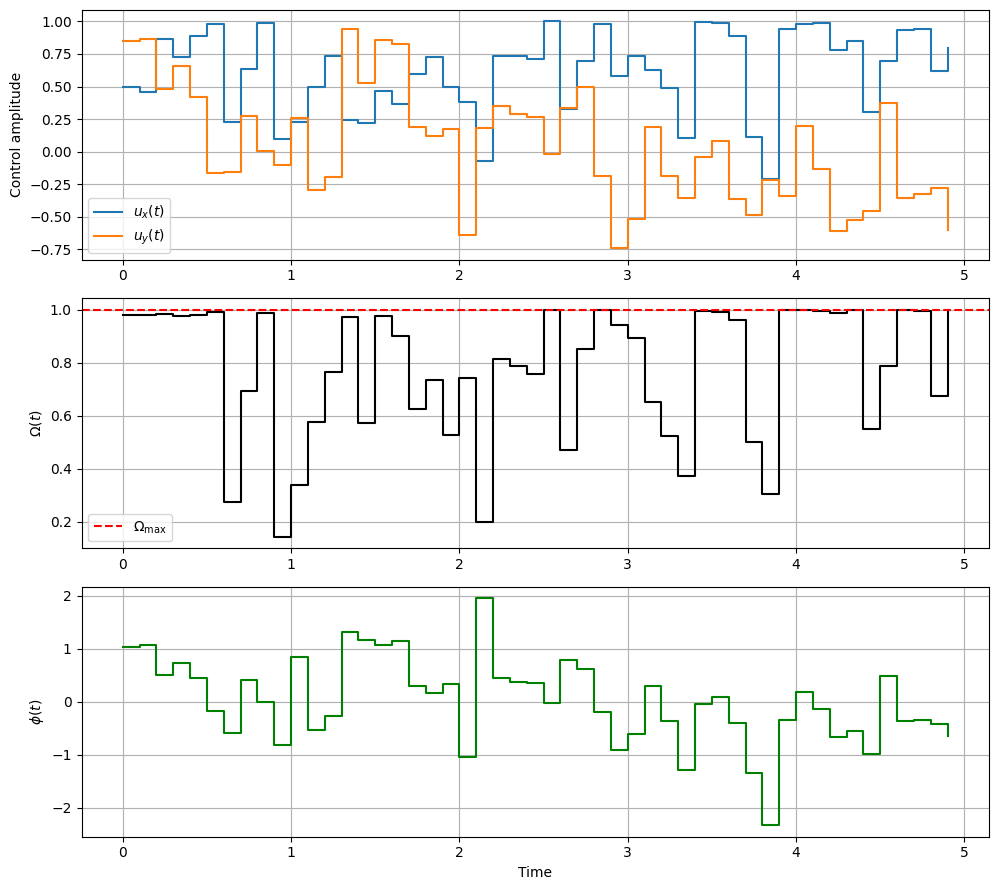

In [9]:
time = np.arange(N) * DT

amplitude = np.sqrt(best_ux**2 + best_uy**2)
phase = np.arctan2(best_uy, best_ux)

fig, axes = plt.subplots(3, 1, figsize=(10, 9))

axes[0].step(time, best_ux, where="post", label=r"$u_x(t)$")
axes[0].step(time, best_uy, where="post", label=r"$u_y(t)$")
axes[0].set_ylabel("Control amplitude")
axes[0].legend()
axes[0].grid()

axes[1].step(time, amplitude, where="post", c="black")
axes[1].axhline(
    OMEGA_MAX,
    linestyle="--",
    label=r"$\Omega_{\max}$",
    c="red"
)
axes[1].set_ylabel(r"$\Omega(t)$")
axes[1].legend()
axes[1].grid()

axes[2].step(time, phase, where="post", c="green")
axes[2].set_ylabel(r"$\phi(t)$")
axes[2].set_xlabel("Time")
axes[2].grid()

plt.tight_layout()
plt.show()

In [10]:
_, autodiff_gradient = scipy_objective(best_run["pulses"][-1], DELTA, DT, U_target)

indices_to_check = [0, 10, 25, 50, 75, 99]

for index in indices_to_check:

    numerical = finite_difference_gradient(DELTA, best_run["pulses"][-1], DT, U_target, index)

    automatic = autodiff_gradient[index]

    print(
        f"Parameter {index:3d} | "
        f"JAX = {automatic:.8e} | "
        f"Finite difference = {numerical:.8e} | "
        f"Difference = {np.abs(automatic - numerical):.8e}"
    )

Parameter   0 | JAX = -1.30890415e-08 | Finite difference = -1.32116540e-08 | Difference = 1.22612482e-10
Parameter  10 | JAX = -1.13911064e-08 | Finite difference = -1.11577414e-08 | Difference = 2.33364972e-10
Parameter  25 | JAX = -9.47978982e-09 | Finite difference = -9.60342916e-09 | Difference = 1.23639345e-10
Parameter  50 | JAX = -6.95644871e-09 | Finite difference = -7.04991621e-09 | Difference = 9.34675004e-11
Parameter  75 | JAX = -9.93044847e-09 | Finite difference = -9.99200722e-09 | Difference = 6.15587519e-11
Parameter  99 | JAX = 6.32811485e-09 | Finite difference = 6.49480469e-09 | Difference = 1.66689849e-10


Automatic differentiation is central to our optimization, so we need to verify that the gradients it produces are correct.

We use finite differences to independently approximate the gradient:
$$
\frac{\partial J}{\partial u_i}
\approx
\frac{J(\mathbf{u}+\varepsilon\mathbf{e}_i)
-J(\mathbf{u}-\varepsilon\mathbf{e}_i)}{2\varepsilon}
$$

We then compare these numerical estimates with the gradients calculated by JAX.

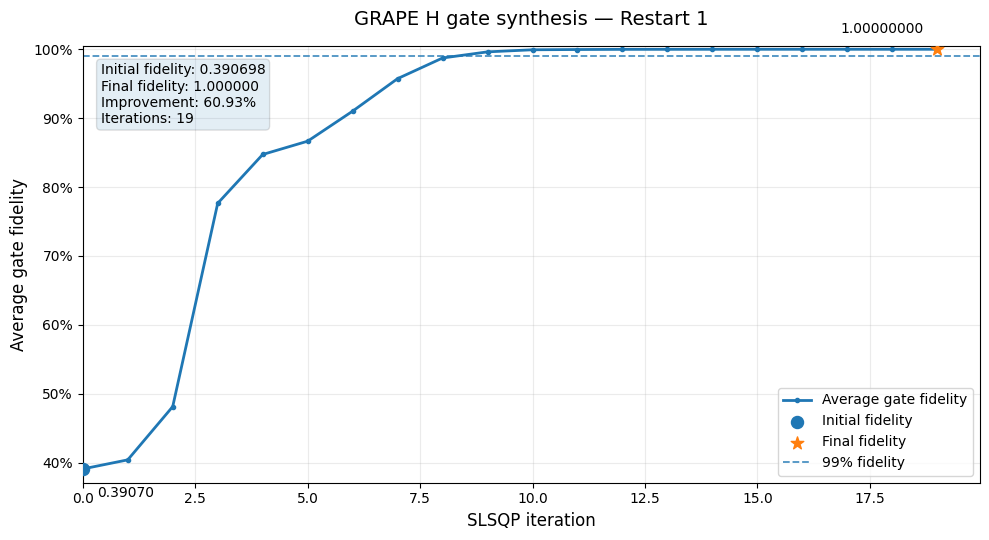

In [11]:
fidelities = np.asarray(best_run["fidelities"])
iterations = np.arange(len(fidelities))

initial_fidelity = fidelities[0]
final_fidelity = fidelities[-1]

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.plot(iterations, fidelities, linewidth=2, marker="o", markersize=3, label="Average gate fidelity")

ax.scatter(iterations[0], initial_fidelity, s=75, zorder=3, label="Initial fidelity")
ax.scatter(iterations[-1], final_fidelity, s=90, marker="*", zorder=3, label="Final fidelity")

ax.axhline(0.99,linestyle="--", linewidth=1.3, alpha=0.8, label="99% fidelity")

ax.annotate(f"{initial_fidelity:.5f}", (iterations[0], initial_fidelity), xytext=(10, -20), textcoords="offset points")
ax.annotate(f"{final_fidelity:.8f}", (iterations[-1], final_fidelity), xytext=(-10, 12), textcoords="offset points", ha="right")

ax.set_xlabel("SLSQP iteration", fontsize=12)
ax.set_ylabel("Average gate fidelity", fontsize=12)
ax.set_title(f"GRAPE {GATE} gate synthesis — Restart {best_run['restart'] + 1}", fontsize=14, pad=15)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_xlim(left=0)
ax.set_ylim(max(0, min(fidelities.min(), 0.99) - 0.02), 1.005)
ax.grid(alpha=0.25)
ax.legend(loc="lower right")

summary = (
    f"Initial fidelity: {initial_fidelity:.6f}\n"
    f"Final fidelity: {final_fidelity:.6f}\n"
    f"Improvement: {(final_fidelity - initial_fidelity) * 100:.2f}%\n"
    f"Iterations: {len(fidelities) - 1}"
)

ax.text(
    0.02, 0.96,
    summary,
    transform=ax.transAxes,
    verticalalignment="top",
    bbox=dict(boxstyle="round", alpha=0.12),
    fontsize=10
)

plt.tight_layout()
plt.show()

The plot shows how the gate fidelity evolves throughout the optimization process. Each iteration corresponds to an update of the control pulse, while the fidelity measures how closely the resulting propagator approximates the target gate.

### 3. Bloch sphere trajectory

In [ ]:
I = np.eye(2, dtype=complex)
X = np.array([[0, 1],[1, 0]], dtype=complex)
Y = np.array([[0, -1j],[1j, 0]], dtype=complex)
Z = np.array([[1, 0],[0, -1]], dtype=complex)
input_states = {
    "|0⟩": np.array([1, 0], dtype=complex),
    "|1⟩": np.array([0, 1], dtype=complex),
    "|+⟩": np.array([1, 1], dtype=complex) / np.sqrt(2)
}
ideal_outputs = {
    name: U_target @ state
    for name, state in input_states.items()
}

def bloch_vector(state):

    alpha, beta = state

    return np.array([
        2.0 * np.real(np.conj(alpha) * beta),
        2.0 * np.imag(np.conj(alpha) * beta),
        abs(alpha)**2 - abs(beta)**2
    ])

def calculate_bloch_trajectory(controls,drift,delta_t,initial_state):

    controls = np.asarray(controls)
    n_segments = len(controls) // 2
    ux = controls[:n_segments]
    uy = controls[n_segments:]
    state = initial_state.copy()
    trajectory = [bloch_vector(state)]

    for k in range(n_segments):
        H = 0.5 * (drift * Z+ ux[k] * X+ uy[k] * Y)
        U = expm(-1j * H * delta_t)
        state = U @ state
        trajectory.append(bloch_vector(state))

    return np.asarray(trajectory)

pulse_history = best_run["pulses"]
fidelity_history = best_run["fidelities"]
n_iterations = len(pulse_history)
selected_indices = sorted(set([0,n_iterations // 2,n_iterations - 1]))
iteration_options = {
    f"Iteration {i} | Fidelity: {fidelity_history[i]:.6f}": i
    for i in selected_indices
}

theta = np.linspace(0, np.pi, 45)
phi = np.linspace(0, 2 * np.pi, 90)
theta, phi = np.meshgrid(theta, phi)
sphere_x = np.sin(theta) * np.cos(phi)
sphere_y = np.sin(theta) * np.sin(phi)
sphere_z = np.cos(theta)

def make_bloch_figure(iteration_index):

    controls = np.asarray(pulse_history[iteration_index])
    trajectories = {
        name: calculate_bloch_trajectory(controls,DELTA,DT,state)
        for name, state in input_states.items()
    }

    ideal_vectors = {
        name: bloch_vector(state)
        for name, state in ideal_outputs.items()
    }

    n_segments = len(controls) // 2
    
    fig = go.Figure()

    fig.add_trace(go.Surface(
        x=sphere_x,
        y=sphere_y,
        z=sphere_z,
        opacity=0.16,
        colorscale=[
            [0, "#303030"],
            [1, "#777777"]
        ],
        showscale=False,
        hoverinfo="skip",
        name="Bloch sphere"
    ))

    # Trajectory colours
    trajectory_colors = {
        "|0⟩": "#FF5555",
        "|1⟩": "#00D5FF",
        "|+⟩": "#FFD166"
    }

    # --------------------------------------------------------
    # Trajectories and moving markers
    # --------------------------------------------------------

    for name, trajectory in trajectories.items():

        color = trajectory_colors[name]

        # Trajectory line
        fig.add_trace(go.Scatter3d(
            x=trajectory[:1, 0],
            y=trajectory[:1, 1],
            z=trajectory[:1, 2],
            mode="lines",
            line=dict(
                color=color,
                width=5
            ),
            name=f"{name} trajectory"
        ))

        # Current state marker
        fig.add_trace(go.Scatter3d(
            x=[trajectory[0, 0]],
            y=[trajectory[0, 1]],
            z=[trajectory[0, 2]],
            mode="markers",
            marker=dict(
                color=color,
                size=6
            ),
            name=f"{name} state",
            showlegend=False
        ))

    # --------------------------------------------------------
    # Ideal output markers
    # --------------------------------------------------------

    for name, vector in ideal_vectors.items():

        fig.add_trace(go.Scatter3d(
            x=[vector[0]],
            y=[vector[1]],
            z=[vector[2]],
            mode="markers",
            marker=dict(
                color=trajectory_colors[name],
                size=9,
                symbol="diamond",
                line=dict(
                    color="white",
                    width=1
                )
            ),
            name=f"{name} ideal output"
        ))

    # --------------------------------------------------------
    # Animation frames
    # --------------------------------------------------------

    frames = []

    for k in range(n_segments + 1):

        frame_data = []

        for name, trajectory in trajectories.items():

            # Trajectory up to segment k
            frame_data.append(go.Scatter3d(
                x=trajectory[:k + 1, 0],
                y=trajectory[:k + 1, 1],
                z=trajectory[:k + 1, 2],
                mode="lines",
                line=dict(
                    color=trajectory_colors[name],
                    width=5
                )
            ))

            # Moving state marker
            frame_data.append(go.Scatter3d(
                x=[trajectory[k, 0]],
                y=[trajectory[k, 1]],
                z=[trajectory[k, 2]],
                mode="markers",
                marker=dict(
                    color=trajectory_colors[name],
                    size=6
                )
            ))

        frames.append(go.Frame(
            name=f"step{k}",
            data=frame_data,
            traces=[1, 2, 3, 4, 5, 6]
        ))

    fig.frames = frames

    # --------------------------------------------------------
    # Layout
    # --------------------------------------------------------

    slider_steps = [
        dict(
            method="animate",
            args=[
                [f"step{k}"],
                dict(
                    mode="immediate",
                    frame=dict(
                        duration=0,
                        redraw=True
                    ),
                    transition=dict(duration=0)
                )
            ],
            label=str(k)
        )
        for k in range(n_segments + 1)
    ]

    fig.update_layout(

        template="plotly_dark",

        width=700,
        height=570,

        paper_bgcolor="#080808",
        plot_bgcolor="#080808",

        margin=dict(
            l=10,
            r=10,
            t=105,
            b=65
        ),

        title=dict(
            text=(
                f"Bloch Sphere | Restart {best_run['restart'] + 1} "
                f"| Iteration {iteration_index}"
            ),
            x=0.5,
            y=0.98,
            xanchor="center",
            yanchor="top",
            font=dict(
                size=17,
                color="white"
            )
        ),

        legend=dict(
            orientation="h",
            yanchor="bottom",
            y=1.06,
            xanchor="center",
            x=0.5,
            font=dict(size=10),
            bgcolor="rgba(0,0,0,0)"
        ),

        scene=dict(

            bgcolor="#080808",

            domain=dict(
                x=[0, 1],
                y=[0.08, 0.95]
            ),

            aspectmode="cube",

            xaxis=dict(
                title="X",
                range=[-1.15, 1.15],
                color="white",
                backgroundcolor="#080808",
                gridcolor="#333333",
                zerolinecolor="#777777"
            ),

            yaxis=dict(
                title="Y",
                range=[-1.15, 1.15],
                color="white",
                backgroundcolor="#080808",
                gridcolor="#333333",
                zerolinecolor="#777777"
            ),

            zaxis=dict(
                title="Z",
                range=[-1.15, 1.15],
                color="white",
                backgroundcolor="#080808",
                gridcolor="#333333",
                zerolinecolor="#777777"
            )
        ),

        # Animation buttons
        updatemenus=[
            dict(
                type="buttons",
                showactive=False,
                x=0.05,
                y=-0.08,
                xanchor="left",
                yanchor="top",
                bgcolor="#222222",
                bordercolor="#555555",
                font=dict(color="white"),
                buttons=[
                    dict(
                        label="▶ Play",
                        method="animate",
                        args=[
                            None,
                            dict(
                                frame=dict(
                                    duration=100,
                                    redraw=True
                                ),
                                transition=dict(duration=0),
                                fromcurrent=True,
                                mode="immediate"
                            )
                        ]
                    ),
                    dict(
                        label="❚❚ Pause",
                        method="animate",
                        args=[
                            [None],
                            dict(
                                frame=dict(
                                    duration=0,
                                    redraw=False
                                ),
                                mode="immediate",
                                transition=dict(duration=0)
                            )
                        ]
                    )
                ]
            )
        ],

        # Segment slider
        sliders=[
            dict(
                active=0,
                x=0.28,
                y=-0.08,
                len=0.68,
                xanchor="left",
                yanchor="top",
                currentvalue=dict(
                    prefix="Control segment: ",
                    font=dict(color="white")
                ),
                font=dict(color="white"),
                bgcolor="#222222",
                bordercolor="#555555",
                steps=slider_steps
            )
        ]
    )

    return fig, trajectories, ideal_vectors


# ============================================================
# 7. WIDGET LAYOUT
# ============================================================

iteration_dropdown = widgets.Dropdown(
    options=iteration_options,
    description="Pulse:",
    layout=widgets.Layout(width="450px")
)

plot_output = widgets.Output(
    layout=widgets.Layout(width="70%")
)

summary_panel = widgets.HTML(
    layout=widgets.Layout(
        width="30%",
        padding="12px",
        background_color="#111111"
    )
)

visualisation_layout = widgets.HBox(
    [plot_output, summary_panel],
    layout=widgets.Layout(
        width="100%",
        align_items="flex-start"
    )
)


# ============================================================
# 8. UPDATE VISUALISATION
# ============================================================

def update_visualisation(change=None):

    iteration_index = iteration_dropdown.value

    fig, trajectories, ideal_vectors = make_bloch_figure(
        iteration_index
    )

    controls = np.asarray(pulse_history[iteration_index])

    n_segments = len(controls) // 2

    ux = controls[:n_segments]
    uy = controls[n_segments:]

    amplitudes = np.sqrt(ux**2 + uy**2)

    controls_2d = controls.reshape(2, n_segments)

    U_actual = np.asarray(
        propagator_jax(DELTA, controls_2d, DT)
    )

    unitarity_error = np.linalg.norm(
        U_actual.conj().T @ U_actual - np.eye(2)
    )

    fidelity = fidelity_history[iteration_index]

    distances = {
        name: np.linalg.norm(
            trajectories[name][-1] - ideal_vectors[name]
        )
        for name in trajectories
    }

    # --------------------------------------------------------
    # Numerical summary
    # --------------------------------------------------------

    summary_panel.value = f"""

    <div style="
        background-color:#111111;
        color:#EEEEEE;
        padding:14px;
        border-radius:8px;
        font-family:Arial;
        font-size:13px;
        line-height:1.7;
    ">

        <h3 style="color:#FFFFFF; margin-top:0;">
            Optimization summary
        </h3>

        <hr style="border-color:#444444;">

        <div style="color:#AAAAAA;">
            GATE FIDELITY
        </div>

        <div style="
            font-size:25px;
            font-weight:bold;
            color:#00D5FF;
        ">
            {fidelity * 100:.6f}%
        </div>

        <hr style="border-color:#444444;">

        <div style="color:#AAAAAA;">
            CONTROL PARAMETERS
        </div>

        Segments: <b>{n_segments}</b><br>
        Maximum amplitude: <b>{np.max(amplitudes):.5f}</b><br>
        Amplitude limit: <b>{OMEGA_MAX:.5f}</b>

        <hr style="border-color:#444444;">

        <div style="color:#AAAAAA;">
            NUMERICAL ACCURACY
        </div>

        Unitarity error:<br>
        <b>{unitarity_error:.3e}</b>

        <hr style="border-color:#444444;">

        <div style="color:#AAAAAA;">
            BLOCH VECTOR ERRORS
        </div>

        |0⟩: <b>{distances['|0⟩']:.3e}</b><br>
        |1⟩: <b>{distances['|1⟩']:.3e}</b><br>
        |+⟩: <b>{distances['|+⟩']:.3e}</b>

    </div>
    """

    with plot_output:

        clear_output(wait=True)

        display(fig)


# ============================================================
# 9. DISPLAY
# ============================================================

iteration_dropdown.observe(
    update_visualisation,
    names="value"
)

display(iteration_dropdown)

display(visualisation_layout)

update_visualisation()


Dropdown(description='Pulse:', layout=Layout(width='450px'), options={'Iteration 0 | Fidelity: 0.390698': 0, '…

To visualize the action of the optimized pulse, we simulate the evolution of several initial qubit states under the controlled Hamiltonian:
$$
H(t)=\frac{1}{2}\left[
\Delta\sigma_z+u_x(t)\sigma_x+u_y(t)\sigma_y
\right]
$$

For each piecewise-constant control segment $k$, the evolution operator is:
$$
U_k=\exp(-iH_k\Delta t)
$$

The state is propagated successively according to:
$$
|\psi_{k+1}\rangle=U_k|\psi_k\rangle
$$

A pure qubit state $|\psi\rangle=\alpha|0\rangle+\beta|1\rangle$ can be represented by a point on the Bloch sphere through its expectation values of the Pauli operators:
$$
\vec r=
\begin{pmatrix}
\langle\sigma_x\rangle\\
\langle\sigma_y\rangle\\
\langle\sigma_z\rangle
\end{pmatrix}
=
\begin{pmatrix}
2\operatorname{Re}(\alpha^*\beta)\\
2\operatorname{Im}(\alpha^*\beta)\\
|\alpha|^2-|\beta|^2
\end{pmatrix}
$$
By calculating this vector after every control segment, we reconstruct the trajectory of the quantum state on the Bloch sphere.

The final states should coincide with the ideal outputs obtained by applying the target gate to the same initial states. The trajectories illustrate how the optimized controls rotate the states during gate execution, while the final positions provide a visual check of the gate's action.